# COMP3122 — Lab 05 — Visualization with Matplotlib and Seaborn
### Week 5 · Chapter 5: Visualization — Matplotlib and Seaborn

**Applied Data Science**

**This lab is graded.** It covers Chapter 5 in the order the chapter covers it.

**How it works:** each task has a cell for your answer, followed by a cell that checks it. Run the check cell and it prints `PASS`, or shows you what it expected.

**How a plot gets checked.** The checker cannot look at your picture, so it looks at your **Axes object** — its title, its labels, the values on its lines, the heights of its bars. That is not a trick. It is the whole point of the chapter: a plot is an object you configure, and everything about it can be asked for by name.

**One rule for the whole lab: every *finished* plot gets a title, an x-label and a y-label.** A cell called `check_labelled` holds you to it, and names whichever of the three is missing. A plot without them is a private note to yourself, not a result.

A few tasks build a plot for a different purpose — to count its Axes, to find out what a wrong index does, or to call a Seaborn function that builds and labels its own Figure. Those ask only for what they need, so where a task's checks differ from the rule, follow the task.

**Store the Figure and the Axes, both.** Almost every task asks you to keep them in named variables — `fig21, ax21 = plt.subplots()` — because the check cell has to reach the Axes afterwards. `plt.plot(...)` on its own gives you nothing to hold.

Work in order. The setup cell builds `weather`, `students` and `enrollments` and defines the checkers, so run it first. If a check will not pass after five minutes, ask.

Part 4 is the one to slow down for. A box plot packs more meaning into less ink than anything else in this chapter, and it is the easiest one to read confidently and get wrong.

---
## Setup — run this first

In [2]:
# Run this cell once, before you start. It builds the data and defines the checkers.
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

weather = pd.DataFrame(
    {
        "Mon": [22, 30, 18, 28],
        "Tue": [24, 31, 19, 27],
        "Wed": [25, 33, 19, 26],
        "Thu": [27, 34, 20, 25],
        "Fri": [26, 33, 21, 26],
        "Sat": [25, 32, 20, 27],
        "Sun": [23, 30, 19, 28],
    },
    index=["Toronto", "Cairo", "Tokyo", "Sydney"],
)

enrollments = pd.DataFrame({
    "course":   ["COMP3122", "COMP3122", "COMP1011", "COMP1011", "COMP2152", "COMP2152"],
    "section":  ["A", "B", "A", "B", "A", "B"],
    "enrolled": [38, 42, 35, 28, 40, 22],
    "capacity": [40, 40, 40, 40, 40, 40],
    "delivery": ["in-person", "in-person", "online", "online", "hybrid", "hybrid"],
})

students = pd.DataFrame({
    "student_id":  ["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8"],
    "program":     ["SE", "SE", "SE", "DS", "DS", "DS", "IT", "IT"],
    "hours_week":  [12,    8,    4,    14,   10,   6,    9,    5  ],
    "attendance":  [95,    88,   70,   98,   90,   75,   85,   72 ],
    "final_score": [88,    80,   65,   92,   84,   70,   78,   68 ],
})

# Untouched copies, so the Task 7.4 guard can tell whether a frame was reassigned.
WEATHER_AT_START = weather.copy()
STUDENTS_AT_START = students.copy()
ENROLLMENTS_AT_START = enrollments.copy()

cities = ["Toronto", "Cairo", "Tokyo", "Sydney"]
days   = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def check(label, got, want):
    """Compare your answer with the expected value. Prints PASS or NOT YET.

    `got` may be a value, or a zero-argument function producing one. The second
    form is used wherever the check has to reach into your answer first — take a
    title off an Axes, round a number, index into a list. Before the answer is
    filled in that would raise, and a traceback where a hint should be is not
    helpful, so it is caught and reported as NOT YET instead.
    """
    if callable(got):
        try:
            got = got()
        except Exception as e:
            print(f"NOT YET  {label}")
            print(f"        your answer raised {type(e).__name__}: {e}")
            return

    def _fail(why=None):
        print(f"NOT YET  {label}")
        if why:
            print(f"        {why}")
        print(f"        you gave: {got!r}")
        print(f"        expected: {want!r}")

    PANDAS = (pd.Series, pd.DataFrame)
    if isinstance(want, PANDAS) or isinstance(got, PANDAS):
        if type(got) is not type(want):
            return _fail(f"wrong type — got {type(got).__name__}, expected {type(want).__name__}")
        if list(got.index) != list(want.index):
            return _fail("the row labels do not match")
        if isinstance(want, pd.DataFrame) and list(got.columns) != list(want.columns):
            return _fail("the column labels do not match")
        try:
            ok = bool(got.equals(want))
        except Exception:
            ok = False
    else:
        g, w = np.asarray(got), np.asarray(want)
        try:
            if g.shape == w.shape and g.dtype.kind in "fc" and w.dtype.kind in "fc":
                ok = bool(np.allclose(g, w))   # decimals: allow a tiny rounding difference
            else:
                ok = bool(np.array_equal(g, w))
        except Exception:
            ok = False

    if ok:
        print(f"PASS  {label}")
    else:
        _fail()


def check_labelled(label, ax):
    """The four-line minimum, checked on a real Axes.

    Chapter 5 asks every finished plot for a title, an x-label and a y-label.
    This is the cell that holds you to it, and it names whichever one is missing
    rather than just refusing the answer.

    Like `check`, `ax` may be a zero-argument function instead of an Axes, for
    the cases where reaching the Axes could itself fail before you have answered.
    """
    if callable(ax) and not hasattr(ax, "get_title"):
        try:
            ax = ax()
        except Exception as e:
            print(f"NOT YET  {label}")
            print(f"        reaching that Axes raised {type(e).__name__}: {e}")
            return
    if not hasattr(ax, "get_title"):
        print(f"NOT YET  {label}")
        print(f"        that is a {type(ax).__name__}, not an Axes — did you store `fig`"
              f" where you meant `ax`?")
        return
    parts = (("title", ax.get_title()), ("x-label", ax.get_xlabel()),
             ("y-label", ax.get_ylabel()))
    missing = [name for name, value in parts if not value.strip()]
    if missing:
        print(f"NOT YET  {label}")
        print(f"        missing: {', '.join(missing)}")
        print(f"        you have: title={ax.get_title()!r}, x={ax.get_xlabel()!r},"
              f" y={ax.get_ylabel()!r}")
    else:
        print(f"PASS  {label}")


def raises(fn):
    """Run fn() and return the name of the exception it raised, or 'no error'.

    Several tasks ask you to find out what a wrong line actually does. Guessing
    is not the same as knowing, and this is how you check.
    """
    try:
        fn()
    except Exception as e:
        return type(e).__name__
    return "no error"


# ---- Helpers the check cells use to read a plot's data. You never call these. ----
def _span(artist):
    """Bottom and top of a box, whether it is drawn as a line or as a filled patch."""
    y = artist.get_ydata() if hasattr(artist, "get_ydata") else artist.get_path().vertices[:, 1]
    return (round(float(min(y)), 2), round(float(max(y)), 2))


def _box_spans_by_label(ax):
    """{tick label: (bottom, top)} for every box on a Seaborn box plot, in any order."""
    ticks = dict(zip([round(float(t), 3) for t in ax.get_xticks()],
                     [t.get_text() for t in ax.get_xticklabels()]))
    out = {}
    for p in ax.patches:
        x = p.get_path().vertices[:, 0]
        centre = round(float((min(x) + max(x)) / 2), 3)
        out[ticks.get(centre, f"x={centre}")] = _span(p)
    return out


def _points_by_legend(ax):
    """Every scatter point as (x, y, legend name of its colour), sorted."""
    legend = ax.get_legend()
    colour_to_name = {}
    for handle, text in zip(legend.legend_handles, legend.get_texts()):
        c = handle.get_markerfacecolor() if hasattr(handle, "get_markerfacecolor") \
            else handle.get_facecolor()[0]
        colour_to_name[tuple(round(float(v), 3) for v in list(c)[:3])] = text.get_text()
    coll = ax.collections[0]
    pts = coll.get_offsets().tolist()
    cols = coll.get_facecolors()
    return sorted((float(x), float(y),
                   colour_to_name.get(tuple(round(float(v), 3) for v in cols[i][:3]), "?"))
                  for i, (x, y) in enumerate(pts))


def _heatmap_numbers(ax):
    """Every number written on a heatmap as (row, column, value), sorted."""
    out = []
    for t in ax.texts:
        x, y = t.get_position()
        try:
            out.append((int(y), int(x), float(t.get_text())))
        except ValueError:
            pass
    return sorted(out)


print("Ready. weather:", weather.shape, " students:", students.shape,
      " enrollments:", enrollments.shape)
print("matplotlib", plt.matplotlib.__version__, " seaborn", sns.__version__,
      " pandas", pd.__version__)


Ready. weather: (4, 7)  students: (8, 5)  enrollments: (6, 5)
matplotlib 3.11.2  seaborn 0.13.2  pandas 3.0.6


---
## Part 1 — The Figure and the Axes  ·  §5.1

Two objects, and almost every beginner error in this chapter comes from mixing them up.
The Figure is the canvas. The Axes is one plot on it. You draw on the Axes.

**Task 1.1.** Build a labelled line plot. Create a Figure and an Axes with
`plt.subplots()`, storing them as `fig11` and `ax11`. Plot `[5, 3, 8, 1]` against
`[1, 2, 3, 4]`, then give it a title, an x-label and a y-label.

The words are yours to choose — the check only asks that all three are there.

Text(0, 0.5, 'Value')

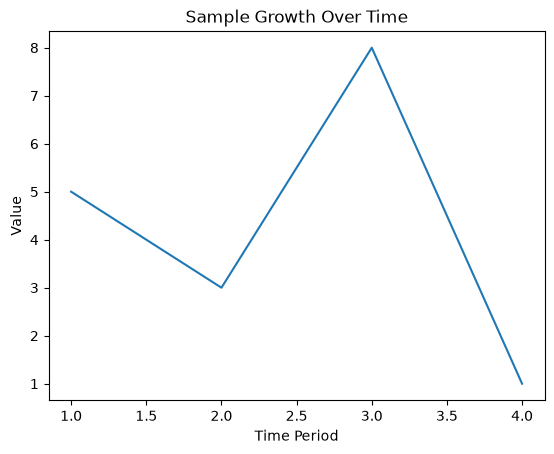

In [3]:
fig11, ax11 = plt.subplots()
ax11.plot([1, 2, 3, 4], [5, 3, 8, 1])
ax11.set_title("Sample Growth Over Time")
ax11.set_xlabel("Time Period")
ax11.set_ylabel("Value")

In [4]:
check('1.1 one line drawn', lambda: len(ax11.lines), 1)
check('1.1 y values',       lambda: list(ax11.lines[0].get_ydata()), [5, 3, 8, 1])
check('1.1 x values',       lambda: list(ax11.lines[0].get_xdata()), [1, 2, 3, 4])
check_labelled('1.1 four-line minimum', ax11)

PASS  1.1 one line drawn
PASS  1.1 y values
PASS  1.1 x values
PASS  1.1 four-line minimum


**Task 1.2.** Find out what the classic mistake actually does, rather than guessing.

A student writes `fig.plot(...)` instead of `ax.plot(...)`. Use the `raises` helper from the
setup cell to capture the **name of the exception** into `t12_error`:

```python
t12_error = raises(lambda: fig11.plot([1, 2, 3], [4, 5, 6]))
```

Then answer, in `t12_draws`: does that call draw an empty plot? `True` or `False`.

In [5]:
t12_error = raises(lambda: fig11.plot([1, 2, 3], [4, 5, 6]))
t12_draws = False

In [6]:
check('1.2 exception name', t12_error, 'AttributeError')
check('1.2 draws nothing?', t12_draws, False)

PASS  1.2 exception name
PASS  1.2 draws nothing?


**Task 1.3.** One Figure can hold several Axes. Build a 2x2 grid with
`fig13, axes13 = plt.subplots(2, 2)`, then store the shape of `axes13` in `t13_shape`
and the number of Axes attached to the Figure in `t13_count`.

Get `t13_count` from the Figure — `fig13.axes` is the list of them. Do not type `4`.

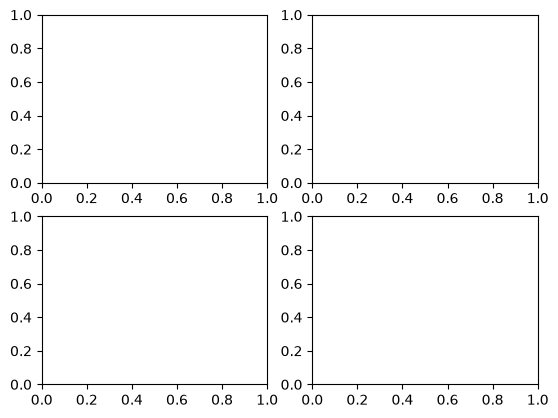

In [7]:
fig13, axes13 = plt.subplots(2,2)
t13_shape = np.shape(axes13)
t13_count = len(fig13.get_axes())

In [8]:
check('1.3 axes array shape', lambda: tuple(t13_shape), (2, 2))
check('1.3 axes on the figure', t13_count, 4)

PASS  1.3 axes array shape
PASS  1.3 axes on the figure


---
## Part 2 — Line plots and scatter plots  ·  §5.2

Both are dots on a grid. The difference is the line, and **the line is a claim**: it says
*this came after that*. Draw it where that is not true and the plot is a lie.

**Task 2.1.** Plot Cairo's week. Take the row with `weather.loc["Cairo"]`, and plot it so
that the **day names** run along the x-axis, not the positions `0` to `6`.

Store the Axes as `ax21`. Label all three.

Text(0, 0.5, 'Weather Value')

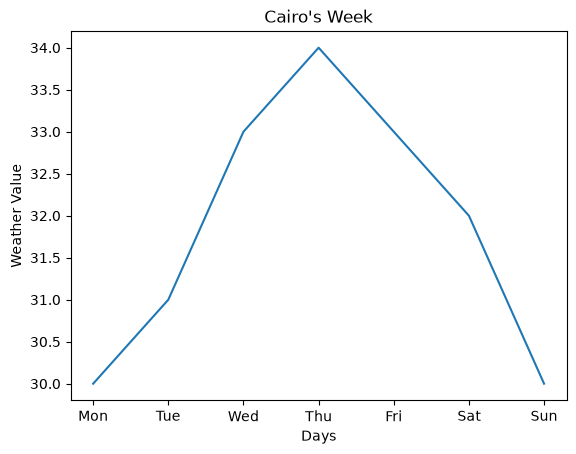

In [9]:
fig21, ax21 = plt.subplots()
ax21.plot(days , weather.loc["Cairo"])

ax21.set_title("Cairo's Week")
ax21.set_xlabel("Days")
ax21.set_ylabel("Weather Value")

In [10]:
check('2.1 y values', lambda: list(ax21.lines[0].get_ydata()), [30, 31, 33, 34, 33, 32, 30])
check('2.1 x axis shows day names',
      lambda: [t.get_text() for t in ax21.get_xticklabels()], days)
check_labelled('2.1 four-line minimum', ax21)

PASS  2.1 y values
PASS  2.1 x axis shows day names
PASS  2.1 four-line minimum


**Task 2.2.** All four cities on one Axes, with a legend that does not sit on top of the
data. Plot one line per city, each with `label=` set to the city name. Give the lines some
headroom with `ax22.set_ylim(16, 40)`, then call `ax22.legend(loc="upper center", ncol=4)`
so the legend sits in the empty space above them.

A `for` loop over `cities` is fine here — this task is about the picture, not the loop.

Text(0, 0.5, 'Weather Value')

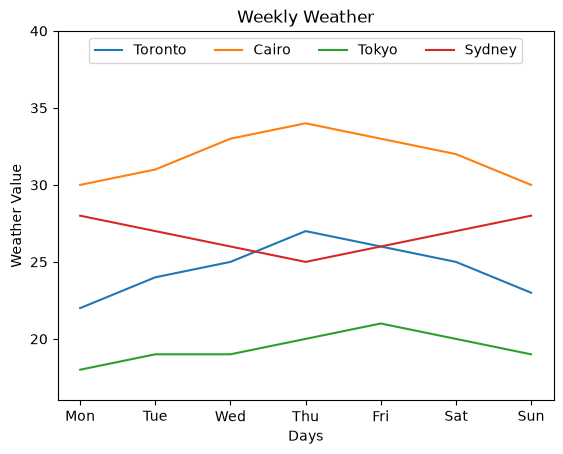

In [11]:
fig22, ax22 = plt.subplots()
for city in cities:
    ax22.plot(days, weather.loc[city], label=city)
    

ax22.legend(loc="upper center", ncol=4)
ax22.set_ylim(16,40)

ax22.set_title("Weekly Weather")
ax22.set_xlabel("Days")
ax22.set_ylabel("Weather Value")

In [12]:
check('2.2 four lines',  lambda: len(ax22.lines), 4)
check('2.2 each line: its label and its data',
      lambda: {l.get_label(): [float(v) for v in l.get_ydata()] for l in ax22.lines},
      {'Toronto': [22.0, 24.0, 25.0, 27.0, 26.0, 25.0, 23.0],
       'Cairo':   [30.0, 31.0, 33.0, 34.0, 33.0, 32.0, 30.0],
       'Tokyo':   [18.0, 19.0, 19.0, 20.0, 21.0, 20.0, 19.0],
       'Sydney':  [28.0, 27.0, 26.0, 25.0, 26.0, 27.0, 28.0]})
check('2.2 days along the x-axis, Mon to Sun',
      lambda: (lambda t: any(t[i:i + 7] == days for i in range(len(t))))(
          [x.get_text() for x in ax22.get_xticklabels()]), True)
check('2.2 headroom for the legend',
      lambda: tuple(round(v, 6) for v in ax22.get_ylim()), (16.0, 40.0))
check('2.2 legend built', lambda: ax22.get_legend() is not None, True)
check('2.2 legend names', lambda: [t.get_text() for t in ax22.get_legend().get_texts()],
      cities)
check_labelled('2.2 four-line minimum', ax22)

PASS  2.2 four lines
PASS  2.2 each line: its label and its data
PASS  2.2 days along the x-axis, Mon to Sun
PASS  2.2 headroom for the legend
PASS  2.2 legend built
PASS  2.2 legend names
PASS  2.2 four-line minimum


**Task 2.3.** Eight students, no order between them. Draw a **scatter** plot of
`hours_week` on the x-axis against `final_score` on the y-axis, from the `students` frame.
Store the Axes as `ax23` and label all three.

Text(0, 0.5, 'Hours Work')

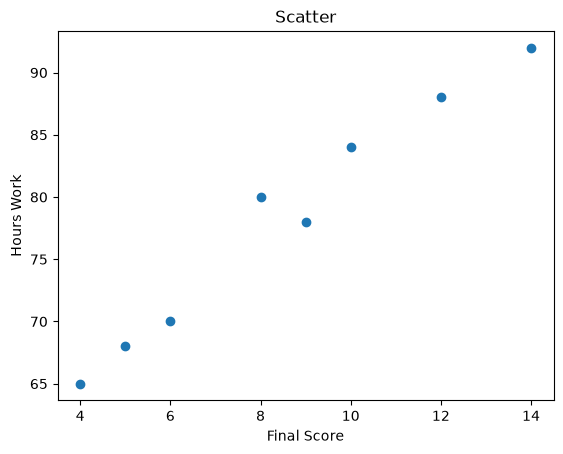

In [13]:
fig23, ax23 = plt.subplots()
ax23.scatter(students.hours_week,students.final_score)
ax23.set_title("Scatter")
ax23.set_xlabel("Final Score")
ax23.set_ylabel("Hours Work")

In [14]:
check('2.3 is a scatter, not a line', lambda: (len(ax23.collections), len(ax23.lines)),
      (1, 0))
check('2.3 eight points', lambda: len(ax23.collections[0].get_offsets()), 8)
check('2.3 the points themselves',
      lambda: sorted(map(tuple, ax23.collections[0].get_offsets().tolist())),
      [(4.0, 65.0), (5.0, 68.0), (6.0, 70.0), (8.0, 80.0),
       (9.0, 78.0), (10.0, 84.0), (12.0, 88.0), (14.0, 92.0)])
check_labelled('2.3 four-line minimum', ax23)

PASS  2.3 is a scatter, not a line
PASS  2.3 eight points
PASS  2.3 the points themselves
PASS  2.3 four-line minimum


**Task 2.4.** Judgement, no plotting. For each situation, store the string `"line"` or
`"scatter"`.

- `t24_a` — one city's temperature on each of thirty consecutive days.
- `t24_b` — the height and the weight of two hundred adults.
- `t24_c` — a company's monthly revenue for two years, in month order.

In [15]:
t24_a = "line"
t24_b = "scatter"
t24_c = "line"

In [16]:
check('2.4 a — days in order', t24_a, 'line')
check('2.4 b — height vs weight', t24_b, 'scatter')
check('2.4 c — monthly revenue', t24_c, 'line')

PASS  2.4 a — days in order
PASS  2.4 b — height vs weight
PASS  2.4 c — monthly revenue


---
## Part 3 — Bar charts and histograms  ·  §5.3

Same rectangles, different x-axis, completely different question. A bar chart has one bar
per **name**. A histogram bins one column of **numbers**.

**Task 3.1.** One bar per section. Build the six labels by joining `course` and `section`
with a hyphen (`"COMP3122-A"` and so on), and use `enrolled` for the heights.

Six labels of that length collide under six bars, so rotate them:
`ax31.tick_params(axis="x", rotation=30)`.

Text(0.5, 0, 'Courses')

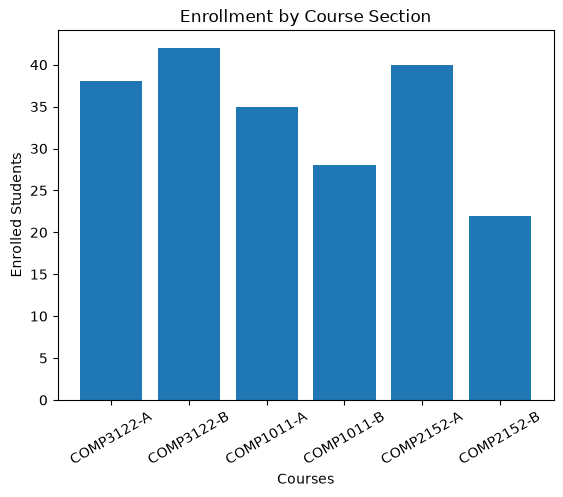

In [17]:
fig31, ax31 = plt.subplots()
ax31.tick_params(axis="x", rotation=30)
ax31.bar(enrollments.course + "-" + enrollments.section, enrollments.enrolled)
ax31.set_title("Enrollment by Course Section")
ax31.set_ylabel("Enrolled Students")
ax31.set_xlabel("Courses")

In [18]:
check('3.1 six bars',    lambda: len(ax31.patches), 6)
check('3.1 bar heights', lambda: [p.get_height() for p in ax31.patches],
      [38, 42, 35, 28, 40, 22])
check('3.1 bar labels',  lambda: [t.get_text() for t in ax31.get_xticklabels()],
      ['COMP3122-A', 'COMP3122-B', 'COMP1011-A', 'COMP1011-B',
       'COMP2152-A', 'COMP2152-B'])
check('3.1 labels rotated', lambda: ax31.get_xticklabels()[0].get_rotation(), 30.0)
check_labelled('3.1 four-line minimum', ax31)

PASS  3.1 six bars
PASS  3.1 bar heights
PASS  3.1 bar labels
PASS  3.1 labels rotated
PASS  3.1 four-line minimum


**Task 3.2.** The shape of all twenty-eight readings. Flatten `weather` to a 1D array with
`weather.to_numpy().flatten()`, then draw a histogram with `bins=5` and
`edgecolor="black"`.

Store the counts that `ax.hist` returns in `t32_counts` — it hands back three things, and
the first is the counts.

Text(0, 0.5, 'Time')

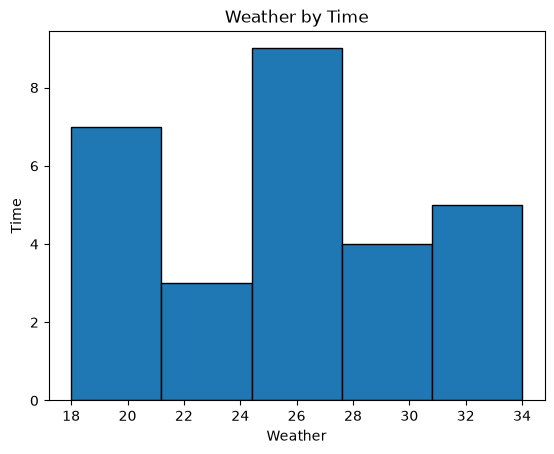

In [19]:
fig32, ax32 = plt.subplots()
t32_counts,_,_ = ax32.hist(weather.to_numpy().flatten(), bins=5, edgecolor="black")
ax32.set_title("Weather by Time")
ax32.set_xlabel("Weather")
ax32.set_ylabel("Time")

In [20]:
check('3.2 five bars',  lambda: len(ax32.patches), 5)
check('3.2 counts',     lambda: [int(c) for c in t32_counts], [7, 3, 9, 4, 5])
check('3.2 bar heights are the counts',
      lambda: [float(p.get_height()) for p in ax32.patches], [7.0, 3.0, 9.0, 4.0, 5.0])
check('3.2 first bin starts at 18', lambda: round(ax32.patches[0].get_x(), 6), 18.0)
check('3.2 every bin is 3.2 wide',
      lambda: [round(p.get_width(), 6) for p in ax32.patches], [3.2] * 5)
check('3.2 bars touch', lambda: round(ax32.patches[0].get_x()
      + ax32.patches[0].get_width() - ax32.patches[1].get_x(), 6), 0.0)
check_labelled('3.2 four-line minimum', ax32)

PASS  3.2 five bars
PASS  3.2 counts
PASS  3.2 bar heights are the counts
PASS  3.2 first bin starts at 18
PASS  3.2 every bin is 3.2 wide
PASS  3.2 bars touch
PASS  3.2 four-line minimum


**Task 3.3.** Now re-draw the same twenty-eight readings with `bins=8`, and store those
counts in `t33_counts`.

Then answer `t33_same_shape`: did the five-bin picture and the eight-bin picture show the
same shape? `True` or `False`.

Text(0, 0.5, 'Time')

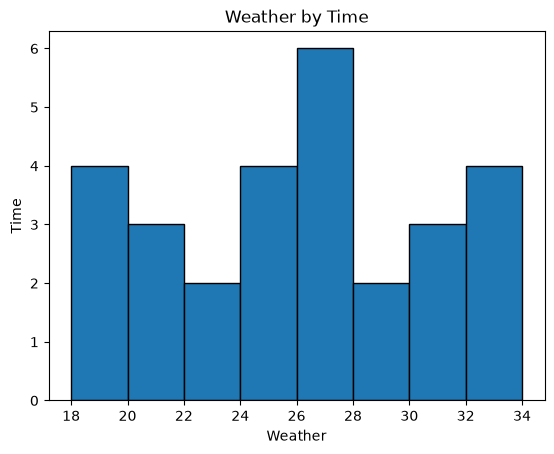

In [21]:
fig33, ax33 = plt.subplots()
t33_counts,_,_ = ax33.hist(weather.to_numpy().flatten(), bins=8, edgecolor="black")
t33_same_shape = False
ax33.set_title("Weather by Time")
ax33.set_xlabel("Weather")
ax33.set_ylabel("Time")

In [22]:
check('3.3 eight bars', lambda: len(ax33.patches), 8)
check('3.3 counts',     lambda: [int(c) for c in t33_counts], [4, 3, 2, 4, 6, 2, 3, 4])
check('3.3 bar heights are the counts',
      lambda: [float(p.get_height()) for p in ax33.patches],
      [4.0, 3.0, 2.0, 4.0, 6.0, 2.0, 3.0, 4.0])
check('3.3 every bin is 2 wide',
      lambda: [round(p.get_width(), 6) for p in ax33.patches], [2.0] * 8)
check('3.3 shape changed', t33_same_shape, False)
check_labelled('3.3 four-line minimum', ax33)

PASS  3.3 eight bars
PASS  3.3 counts
PASS  3.3 bar heights are the counts
PASS  3.3 every bin is 2 wide
PASS  3.3 shape changed
PASS  3.3 four-line minimum


**Task 3.4.** Judgement, no plotting. Store `"bar"` or `"histogram"`.

- `t34_a` — the number of students in each of five programs.
- `t34_b` — the final scores of four hundred students, to see how they are spread.
- `t34_c` — how many customers gave each star rating, one to five.

In [23]:
t34_a = "bar"
t34_b = "histogram"
t34_c = "bar"

In [24]:
check('3.4 a — students per program', t34_a, 'bar')
check('3.4 b — spread of 400 scores', t34_b, 'histogram')
check('3.4 c — star ratings 1-5', t34_c, 'bar')

PASS  3.4 a — students per program
PASS  3.4 b — spread of 400 scores
PASS  3.4 c — star ratings 1-5


---
## Part 4 — Box plots  ·  §5.4

The most compressed plot in the chapter, and the one most often read confidently and
wrongly. Slow down here.

**Task 4.1.** Three programs, in pure Matplotlib. Pull each program's `final_score` values
out of `students`, pass the three groups to `ax41.boxplot(...)` as a list, and name them
with `tick_labels=["SE", "DS", "IT"]`.

Store what `boxplot` returns in `bp41` — it is a dictionary of the drawn pieces.

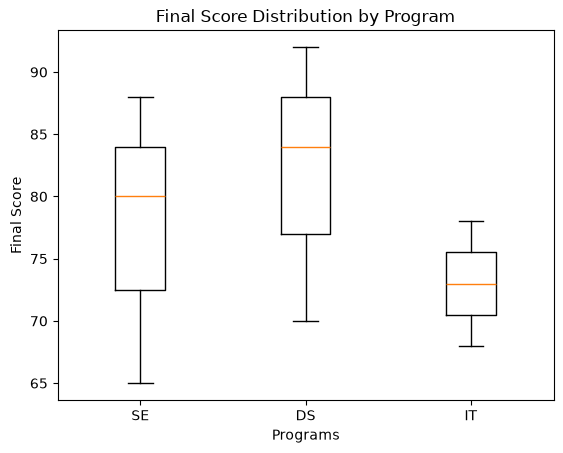

In [28]:
fig41, ax41 = plt.subplots()

# 1. Pull each program's final_score values out of students
se_scores = students[students["program"] == "SE"]["final_score"]
ds_scores = students[students["program"] == "DS"]["final_score"]
it_scores = students[students["program"] == "IT"]["final_score"]

bp41 = ax41.boxplot([se_scores, ds_scores, it_scores], tick_labels=["SE", "DS", "IT"])

ax41.set_ylabel("Final Score")
ax41.set_title("Final Score Distribution by Program")
ax41.set_xlabel("Programs")

plt.show()

In [29]:
check('4.1 three boxes', lambda: len(bp41['boxes']), 3)
check('4.1 group names', lambda: [t.get_text() for t in ax41.get_xticklabels()],
      ['SE', 'DS', 'IT'])
check('4.1 the three medians',
      lambda: [m.get_ydata()[0] for m in bp41['medians']], [80.0, 84.0, 73.0])
check('4.1 each box spans its quartiles',
      lambda: [_span(b) for b in bp41['boxes']], [(72.5, 84.0), (77.0, 88.0), (70.5, 75.5)])
check('4.1 whisker ends',
      lambda: [float(c.get_ydata()[0]) for c in bp41['caps']],
      [65.0, 88.0, 70.0, 92.0, 68.0, 78.0])
check_labelled('4.1 four-line minimum', ax41)

PASS  4.1 three boxes
PASS  4.1 group names
PASS  4.1 the three medians
PASS  4.1 each box spans its quartiles
PASS  4.1 whisker ends
PASS  4.1 four-line minimum


**Task 4.2.** Read the box, with numbers rather than by eye. For the **SE** group's three
scores, compute the 25th percentile, the median and the 75th with `np.percentile`, into
`t42_q1`, `t42_med` and `t42_q3`.

Then count how many of the three SE scores actually fall **inside** that box — between
`t42_q1` and `t42_q3` inclusive — into `t42_inside`.

Predict `t42_inside` before you run it.

In [30]:
se_scores = students[students["program"] == "SE"]["final_score"]

t42_q1 = np.percentile(se_scores, 25)
t42_med = np.percentile(se_scores, 50)
t42_q3 = np.percentile(se_scores, 75)

t42_inside = np.sum((se_scores >= t42_q1) & (se_scores <= t42_q3))

In [31]:
check('4.2 25th percentile', lambda: round(float(t42_q1), 2), 72.5)
check('4.2 median',          lambda: round(float(t42_med), 2), 80.0)
check('4.2 75th percentile', lambda: round(float(t42_q3), 2), 84.0)
check('4.2 scores inside the box', t42_inside, 1)

PASS  4.2 25th percentile
PASS  4.2 median
PASS  4.2 75th percentile
PASS  4.2 scores inside the box


**Task 4.3.** What a box plot can and cannot tell you. `True` or `False` for each.

- `t43_a` — the box gets wider when you have more observations.
- `t43_b` — the line inside the box is the mean.
- `t43_c` — a box plot can show that one group's median is higher **in this sample**.
- `t43_d` — a box plot can establish that the difference between two groups is more than
  chance.

In [32]:
t43_a = False
t43_b = False
t43_c = True
t43_d = False

In [33]:
check('4.3 a — wider with more data', t43_a, False)
check('4.3 b — the line is the mean', t43_b, False)
check('4.3 c — higher in this sample', t43_c, True)
check('4.3 d — more than chance',     t43_d, False)

PASS  4.3 a — wider with more data
PASS  4.3 b — the line is the mean
PASS  4.3 c — higher in this sample
PASS  4.3 d — more than chance


---
## Part 5 — Seaborn  ·  §5.5

Seaborn is not an alternative to Matplotlib. It sits **on top of** it and calls it
underneath, which is why every `set_title` you know still works.

**Task 5.1.** The same three boxes as Task 4.1, in one Seaborn call:
`sns.boxplot(data=students, x="program", y="final_score", ax=ax51)`.

Seaborn fills in the axis labels from the column names. Leave the x-label as it comes, but
**override the y-label** with real words — `"final_score"` with an underscore in it does
not belong in front of a client — and add a title, which Seaborn never does for you.

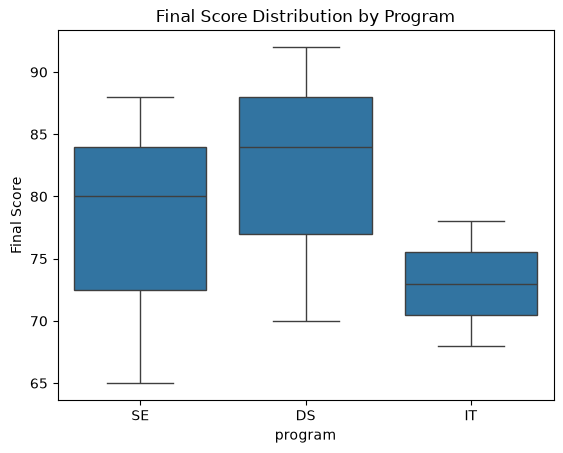

In [36]:
fig51, ax51 = plt.subplots()

sns.boxplot(data=students, x="program", y="final_score", ax=ax51)

ax51.set_ylabel("Final Score")
ax51.set_title("Final Score Distribution by Program")

plt.show()

In [37]:
check('5.1 seaborn labelled the x-axis for you', lambda: ax51.get_xlabel(), 'program')
check('5.1 y-label overridden', lambda: ax51.get_ylabel() != 'final_score', True)
check('5.1 title added by you', lambda: bool(ax51.get_title().strip()), True)
check('5.1 three boxes', lambda: len(ax51.patches), 3)
check('5.1 each program\'s box spans its quartiles, so they are boxes and not bars',
      lambda: _box_spans_by_label(ax51),
      {'SE': (72.5, 84.0), 'DS': (77.0, 88.0), 'IT': (70.5, 75.5)})
check_labelled('5.1 four-line minimum', ax51)

PASS  5.1 seaborn labelled the x-axis for you
PASS  5.1 y-label overridden
PASS  5.1 title added by you
PASS  5.1 three boxes
PASS  5.1 each program's box spans its quartiles, so they are boxes and not bars
PASS  5.1 four-line minimum


**Task 5.2.** `hue=` in one argument. Draw a Seaborn scatter plot of `hours_week` against
`final_score`, coloured by `program`, onto `ax52`. Add a title.

Store the number of distinct colours Seaborn used in `t52_groups` — read it off the legend
rather than typing `3`.

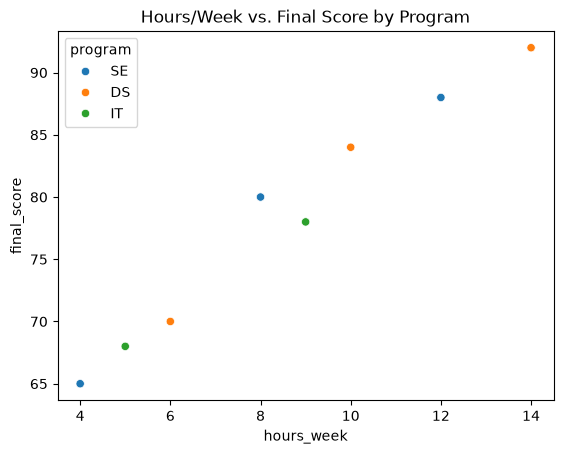

In [39]:
fig52, ax52 = plt.subplots()

sns.scatterplot(data=students,x="hours_week",y="final_score",hue="program",ax=ax52)
ax52.set_title("Hours/Week vs. Final Score by Program")

legend_texts = [text.get_text() for text in ax52.get_legend().get_texts()]
unique_programs = students["program"].unique()
t52_groups = len([label for label in legend_texts if label in unique_programs])

In [40]:
check('5.2 legend built for you', lambda: ax52.get_legend() is not None, True)
check('5.2 three programs in the legend', t52_groups, 3)
check('5.2 legend names', lambda: sorted(t.get_text() for t in
      ax52.get_legend().get_texts()), ['DS', 'IT', 'SE'])
check('5.2 each point is coloured by its own program',
      lambda: _points_by_legend(ax52),
      [(4.0, 65.0, 'SE'), (5.0, 68.0, 'IT'), (6.0, 70.0, 'DS'), (8.0, 80.0, 'SE'),
       (9.0, 78.0, 'IT'), (10.0, 84.0, 'DS'), (12.0, 88.0, 'SE'), (14.0, 92.0, 'DS')])
check('5.2 the eight points, hours on x and score on y',
      lambda: sorted(map(tuple, ax52.collections[0].get_offsets().tolist())),
      [(4.0, 65.0), (5.0, 68.0), (6.0, 70.0), (8.0, 80.0),
       (9.0, 78.0), (10.0, 84.0), (12.0, 88.0), (14.0, 92.0)])
check_labelled('5.2 four-line minimum', ax52)

PASS  5.2 legend built for you
PASS  5.2 three programs in the legend
PASS  5.2 legend names
PASS  5.2 each point is coloured by its own program
PASS  5.2 the eight points, hours on x and score on y
PASS  5.2 four-line minimum


**Task 5.3.** Every pair at once. Call `sns.pairplot` on the three numeric columns of
`students` — `hours_week`, `attendance`, `final_score` — and store the returned grid object
as `g53`.

Note there is no `ax=` here, and no labelling for you to do. `pairplot` is a **figure-level**
function: it builds its own Figure and labels all nine panels from the column names itself.
That is why this task has no `check_labelled`.

Then store the shape of `g53.axes` in `t53_shape`, and the number of individual plots drawn
in `t53_plots`. Derive the second from the first.

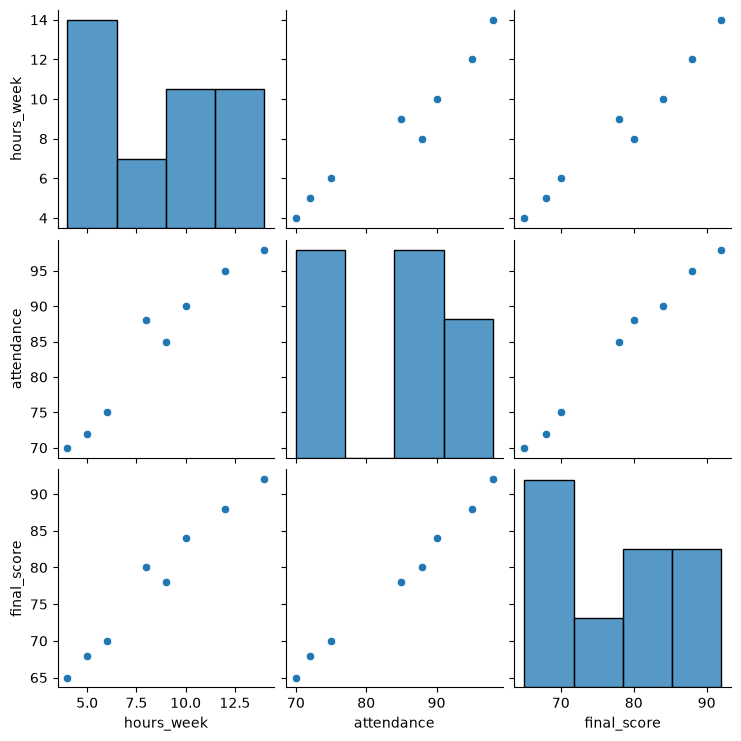

In [41]:
g53 = sns.pairplot(students[["hours_week", "attendance", "final_score"]])

t53_shape = g53.axes.shape
t53_plots = t53_shape[0] * t53_shape[1]

In [42]:
check('5.3 grid shape', lambda: tuple(t53_shape), (3, 3))
check('5.3 plots drawn', t53_plots, 9)

PASS  5.3 grid shape
PASS  5.3 plots drawn


**Task 5.4.** A 2D table as coloured cells. Draw `sns.heatmap` of the whole `weather` frame
onto `ax54`, with `annot=True` so the numbers show. Add a title.

Store the number of coloured cells in `t54_cells`. Derive it from `weather.shape` — do not
type `28`.

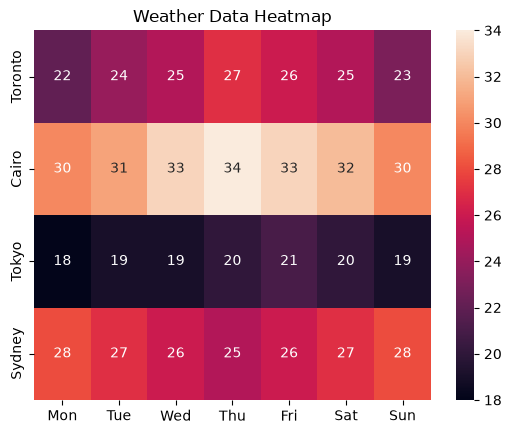

In [43]:
fig54, ax54 = plt.subplots()

sns.heatmap(weather, annot=True, ax=ax54)

ax54.set_title("Weather Data Heatmap")

t54_cells = weather.shape[0] * weather.shape[1]

In [ ]:
check('5.4 cell count', t54_cells, 28)
check('5.4 rows are the cities',
      lambda: [t.get_text() for t in ax54.get_yticklabels()], cities)
check('5.4 columns are the days',
      lambda: [t.get_text() for t in ax54.get_xticklabels()], days)
check('5.4 title added', lambda: bool(ax54.get_title().strip()), True)
check('5.4 the cell values are the temperatures',
      lambda: [float(v) for v in np.asarray(ax54.collections[0].get_array()).ravel()],
      [float(v) for v in [22, 24, 25, 27, 26, 25, 23, 30, 31, 33, 34, 33, 32, 30,
                          18, 19, 19, 20, 21, 20, 19, 28, 27, 26, 25, 26, 27, 28]])
check('5.4 each cell shows its own temperature',
      lambda: _heatmap_numbers(ax54),
      [(r, c, float(v)) for r, row in enumerate([[22, 24, 25, 27, 26, 25, 23],
                                                  [30, 31, 33, 34, 33, 32, 30],
                                                  [18, 19, 19, 20, 21, 20, 19],
                                                  [28, 27, 26, 25, 26, 27, 28]])
       for c, v in enumerate(row)])

PASS  5.4 cell count
PASS  5.4 rows are the cities
PASS  5.4 columns are the days
PASS  5.4 title added
PASS  5.4 the cell values are the temperatures
PASS  5.4 each cell shows its own temperature


---
## Part 6 — Several plots on one figure  ·  §5.6

One Figure, several Axes, and one indexing trap that catches everybody exactly once.

**Task 6.1.** A 2x2 grid of four different plots. Build it with
`plt.subplots(2, 2, figsize=(10, 8))`, then draw:

- `axes61[0, 0]` — a line plot of Toronto's week
- `axes61[0, 1]` — a scatter of `hours_week` against `final_score`
- `axes61[1, 0]` — a bar chart of the six section enrolments
- `axes61[1, 1]` — a histogram of the twenty-eight readings

Title each one, and finish with `fig61.tight_layout()`.

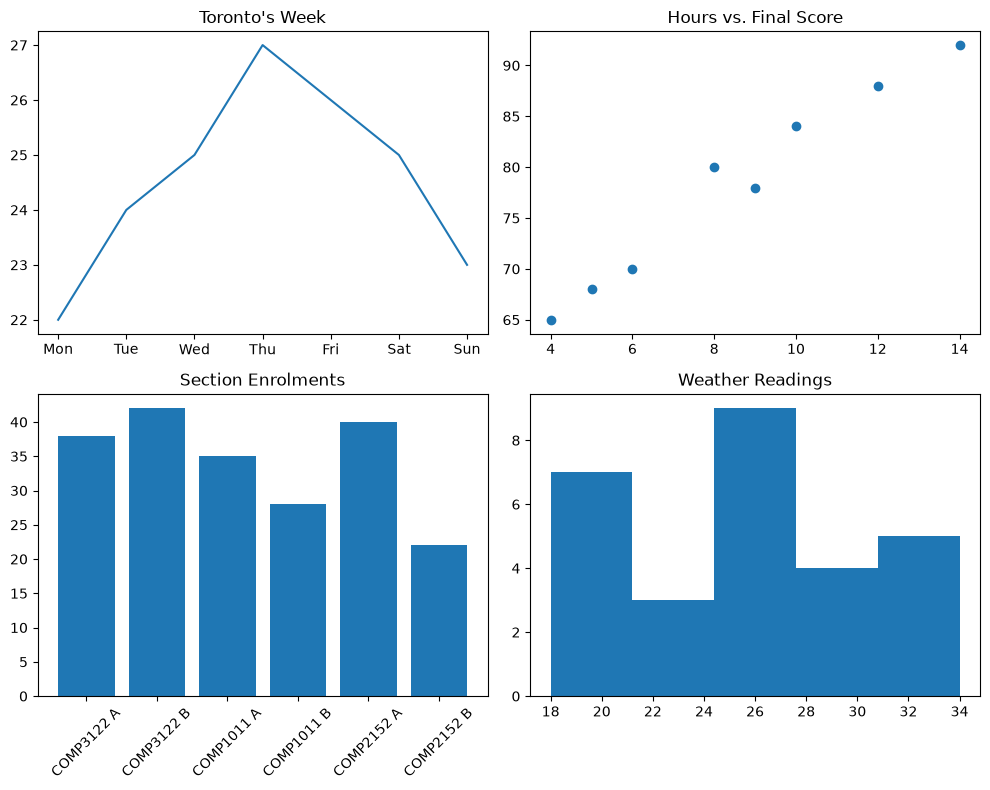

In [47]:
fig61, axes61 = plt.subplots(2, 2, figsize=(10, 8))

axes61[0, 0].plot(days, weather.loc["Toronto"])
axes61[0, 0].set_title("Toronto's Week")

axes61[0, 1].scatter(students["hours_week"], students["final_score"])
axes61[0, 1].set_title("Hours vs. Final Score")

section_labels = enrollments["course"] + " " + enrollments["section"]
axes61[1, 0].bar(section_labels, enrollments["enrolled"])
axes61[1, 0].set_title("Section Enrolments")
axes61[1, 0].tick_params(axis="x", rotation=45)

axes61[1, 1].hist(weather.values.flatten(), bins=5)
axes61[1, 1].set_title("Weather Readings")

fig61.tight_layout()

In [48]:
check('6.1 four axes on the figure', lambda: len(fig61.axes), 4)
check('6.1 grid shape', lambda: tuple(axes61.shape), (2, 2))
check('6.1 every panel titled',
      lambda: all(a.get_title().strip() for a in fig61.axes), True)
check('6.1 top-left is a line', lambda: len(axes61[0, 0].lines), 1)
check('6.1 top-right is a scatter', lambda: len(axes61[0, 1].collections), 1)
check('6.1 bottom-left has six bars', lambda: len(axes61[1, 0].patches), 6)
check('6.1 bottom-right has five bars', lambda: len(axes61[1, 1].patches), 5)
check('6.1 top-left is Toronto',
      lambda: [float(v) for v in axes61[0, 0].lines[0].get_ydata()],
      [22.0, 24.0, 25.0, 27.0, 26.0, 25.0, 23.0])
check('6.1 top-right is hours against score',
      lambda: sorted(map(tuple, axes61[0, 1].collections[0].get_offsets().tolist())),
      [(4.0, 65.0), (5.0, 68.0), (6.0, 70.0), (8.0, 80.0),
       (9.0, 78.0), (10.0, 84.0), (12.0, 88.0), (14.0, 92.0)])
check('6.1 bottom-left heights are the enrolments',
      lambda: [float(p.get_height()) for p in axes61[1, 0].patches],
      [38.0, 42.0, 35.0, 28.0, 40.0, 22.0])
check('6.1 bottom-right heights are the counts',
      lambda: [float(p.get_height()) for p in axes61[1, 1].patches],
      [7.0, 3.0, 9.0, 4.0, 5.0])

PASS  6.1 four axes on the figure
PASS  6.1 grid shape
PASS  6.1 every panel titled
PASS  6.1 top-left is a line
PASS  6.1 top-right is a scatter
PASS  6.1 bottom-left has six bars
PASS  6.1 bottom-right has five bars
PASS  6.1 top-left is Toronto
PASS  6.1 top-right is hours against score
PASS  6.1 bottom-left heights are the enrolments
PASS  6.1 bottom-right heights are the counts


**Task 6.2.** The trap. Build a row of three with `plt.subplots(1, 3)` and store the shape
of `axes62` in `t62_shape`.

Then find out — do not guess — what `axes62[0, 1]` does, using `raises`, into `t62_error`.
Finally, put the correct way to reach the **middle** plot's title in `t62_middle`: set that
middle Axes' title to `"middle"` and read it back.

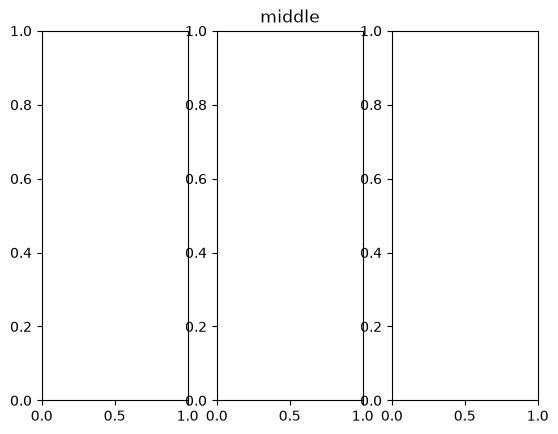

In [51]:
fig62, axes62 = plt.subplots(1, 3)
t62_shape = axes62.shape

t62_error = "IndexError"

axes62[1].set_title("middle")
t62_middle = axes62[1].get_title()

In [50]:
check('6.2 shape is one-dimensional', lambda: tuple(t62_shape), (3,))
check('6.2 two indices raise', t62_error, 'IndexError')
check('6.2 one index works', t62_middle, 'middle')

PASS  6.2 shape is one-dimensional
NOT YET  6.2 two indices raise
        you gave: IndexError()
        expected: 'IndexError'
PASS  6.2 one index works


**Task 6.3.** Keep the two-dimensional array. Build the same row of three, but pass `squeeze=False`, and
store the shape in `t63_shape`.

Then store, in `t63_rule`, the number of indices you need when both dimensions are greater
than one: `1` or `2`.

In [ ]:
fig63, axes63 = None, None
t63_shape = None
t63_rule = None

In [ ]:
check('6.3 squeeze=False keeps two dimensions', lambda: tuple(t63_shape), (1, 3))
check('6.3 indices needed when both dims > 1', t63_rule, 2)
check('6.3 middle plot reachable as [0, 1]',
      lambda: axes63[0, 1] is not None, True)

---
## Part 7 — Reading a plot honestly  ·  §5.7

Every number on a chart can be correct while the chart still gives the wrong impression.
This part is Learning Objective 7, and it is the part that outlives the syntax.

**Task 7.1.** The same four numbers, twice. Regional sales are North 102, South 104,
East 103, West 106.

Build a 1x2 grid. Draw the same bar chart on both panels. Leave the left one alone, and on
the right call `set_ylim(100, 107)`. Title them so a reader can tell which is which — but
do **not** call either one honest or dishonest.

Store both panels' y-limits in `t71_left` and `t71_right`.

In [ ]:
fig71, axes71 = None, None
t71_left = None
t71_right = None

In [ ]:
check('7.1 left panel starts at 0', lambda: round(t71_left[0], 6), 0.0)
check('7.1 right panel starts at 100', lambda: tuple(round(v, 6) for v in t71_right),
      (100.0, 107.0))
check('7.1 four bars on each',
      lambda: (len(axes71[0].patches), len(axes71[1].patches)), (4, 4))
check('7.1 the same four sales on both panels',
      lambda: [[float(p.get_height()) for p in a.patches] for a in axes71],
      [[102.0, 104.0, 103.0, 106.0], [102.0, 104.0, 103.0, 106.0]])
check_labelled('7.1 left panel labelled',  lambda: axes71[0])
check_labelled('7.1 right panel labelled', lambda: axes71[1])

**Task 7.2.** Put a number on the distortion. Using the same four sales values:

- `t72_real_gap` — the real percentage gap between the largest and the smallest, rounded
  to one decimal.
- `t72_apparent` — on the right-hand panel every bar is drawn from 100 upward, so its
  visible height is `value - 100`. Store how many times taller the West bar **looks** than
  the North bar, rounded to one decimal.

In [ ]:
t72_real_gap = None
t72_apparent = None

In [ ]:
check('7.2 real gap, per cent', t72_real_gap, 3.9)
check('7.2 apparent height ratio', t72_apparent, 3.0)

**Task 7.3.** The judgement, which is not the obvious one. `True` or `False`.

- `t73_a` — a bar chart's y-axis must always start at zero.
- `t73_b` — a truncated y-axis is sometimes the right choice.
- `t73_c` — the axis **label** (`"Units sold"`) tells a reader where the axis starts.
- `t73_d` — the **tick labels** tell a reader where the axis starts.

In [ ]:
t73_a = None
t73_b = None
t73_c = None
t73_d = None

In [ ]:
check('7.3 a — must always start at zero', t73_a, False)
check('7.3 b — sometimes right to truncate', t73_b, True)
check('7.3 c — the axis label shows the scale', t73_c, False)
check('7.3 d — the tick labels show the scale', t73_d, True)

**Task 7.4.** GUARD — not a task. Run this check before you submit.

It reads `weather` and `students` themselves and confirms you have not overwritten either
one earlier in the notebook. Nothing to fill in.

In [ ]:
# Nothing to write here. Just run the check cell below.

In [ ]:
check('7.4 GUARD weather unchanged', lambda: weather.equals(WEATHER_AT_START), True)
check('7.4 GUARD students unchanged', lambda: students.equals(STUDENTS_AT_START), True)
check('7.4 GUARD enrollments unchanged',
      lambda: enrollments.equals(ENROLLMENTS_AT_START), True)

---
## Finish

Choose **Kernel → Restart Kernel and Run All Cells** one last time. If every check prints `PASS` from a clean start, your work is reproducible and you are done.

Then look back at two of your figures with your own eyes, because no check can do it for you: **Task 3.1**, where the six section labels should be readable rather than smeared together, and **Task 6.1**, where the four titles should not be sitting on top of the plots above them. Present but illegible is the same as absent.

**If Task 4.2 surprised you, that is the intended difficulty.** The box holds the middle half *of the distribution*, which is an interval — not a promise that half your dots will be inside it. With three observations, one of them was. Re-read §5.4 and bring the question to class.

**One habit to take with you.** Before you fit a model to anything — and next week you start fitting models — plot it first. In this lab's eight students, attendance and final score move together almost perfectly, and a single pairplot would have shown you that in about a second. Always look at the data before you model it.

---
## Your submission line

Run the cell below and paste **the line it prints** into *Lab 5 — submit* on D2L. Nothing else — not the address bar of this notebook, which carries a port number that stops working when your server restarts. The line is built from your account name, so it always works.

In [ ]:
# Run this cell. Copy the line it prints into 'Lab 5 -- submit' on D2L. Nothing else.
from pathlib import Path
account = Path.home().name                                   # your gblearn account name
print(f'http://{account}.gblearn.com/python/?open=comp3122/labs/lab05/COMP3122-Lab05-Student.ipynb')